In [39]:
#Friedmann equation: ((da /dt) / a)^2 = (8*pi*G*rho) / 3 - k * c^2 / a^2

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt2

#define constants
G = 6.67e-11
c = 2.99e8
L = 1e26
rho = 8.5e-26

#define da / dt
def f(a, k):
    if(a <= 0):
        return 0.0
    return np.sqrt(max( 8 * np.pi * G * rho / (3 * a) - k * c * c / (L * L), 0.0))

In [40]:
#using RK4 method to solve ODE

#define t_max
t1 = 5e17

#define steps
h = 1e12

def rk4(k):
    t0 = 0.0
    a0 = 0.01
    times = [t0]
    scales = [a0]
    while t0 < t1:
        if k == 1 and f(a0, k) < 1e-25:
            break
        k1 = f(a0, k)
        k2 = f(a0 + h * k1 / 2, k)
        k3 = f(a0 + h * k2 / 2, k)
        k4 = f(a0 + h * k3, k)
        a1 = a0 + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    
        if k == 1 and a1 >= (8 * np.pi * G * rho * L * L / (3 * c * c)):
            break
        
        t0 = t0 + h
        a0 = a1
        times.append(t0)
        scales.append(a0)
    return np.array(times), np.array(scales)

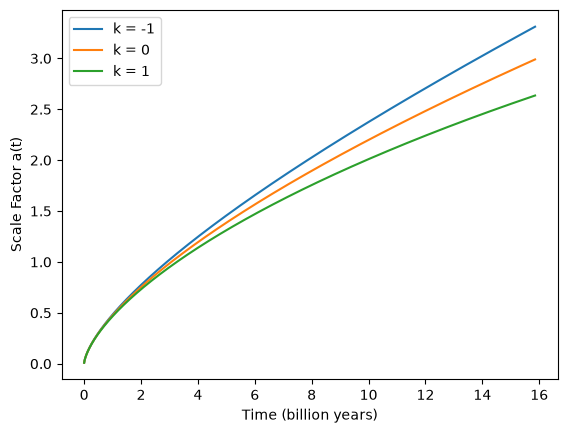

In [29]:
#plot for k = -1, 0, 1

for k in [-1, 0, 1]:
    t, a = rk4(k)
    plt.plot(t / 3.154e16, a, label=f"k = {k}")

plt.xlabel("Time (billion years)")
plt.ylabel("Scale Factor a(t)")
plt.legend()
plt.show()

In [46]:
#Simplify Friedmann Equation: da / dtau = sqrt( Omega_m,0 / a + Omega_k,0 ) where Omega_k,0 = 1 - Omega_m,0

def simplified_f(a, omega):
    return np.sqrt(max(omega / a + 1 - omega, 0))

In [52]:
#using RK4 to solve the simplified ODE

#define t_max
t1 = 5

#define step size
h = 0.001

def rk4_omega(omega):
    t0 = 0.0
    a0 = 0.01
    times = [t0]
    scales = [a0]
    while t0 < t1:
        k1 = simplified_f(a0, omega)
        k2 = simplified_f(a0 + h * k1 / 2, omega)
        k3 = simplified_f(a0 + h * k2 / 2, omega)
        k4 = simplified_f(a0 + h * k3, omega)
        a1 = a0 + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    
        if omega > 1 and omega / a1 + 1 - omega <= 0: 
            break
        
        t0 = t0 + h
        a0 = a1
        times.append(t0)
        scales.append(a0)
    return np.array(times), np.array(scales)

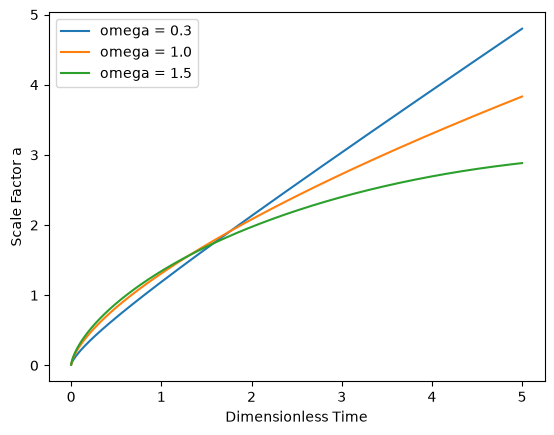

In [53]:
#plot for omega = 0.3, 1.0, 1.5

for omega in [0.3, 1.0, 1.5]:
    t, a = rk4_omega(omega)
    plt2.plot(t, a, label=f"omega = {omega}")

plt2.xlabel("Dimensionless Time")
plt2.ylabel("Scale Factor a")
plt2.legend()
plt2.show()